# 🫀 Classification Binaire — Normal vs Malade

## 🔄 Transformation du problème

| Version précédente | Cette version |
|---|---|
| 4 classes (ASD, Normal, PDA, VSD) | **2 classes (Normal, Malade)** |
| Dataset équilibré | **Dataset déséquilibré** |
| Accuracy globale | **F1-score + ROC-AUC** |

## 📊 Distribution après regroupement

| Classe | Images | Source |
|---|---|---|
| **Normal** | 208 | Classe Normal originale |
| **Malade** | 620 | ASD (194) + PDA (216) + VSD (210) |
| **Total** | 828 | |

**Ratio de déséquilibre : 1 Normal pour 3 Malades** → nécessite une gestion spécifique.

## 🛠️ Stratégie anti-déséquilibre

1. **Weighted Loss** — pénalise plus les erreurs sur la classe minoritaire (Normal)
2. **WeightedRandomSampler** — surreprésentte Normal dans chaque batch
3. **Data Augmentation** — diversifie les images d'entraînement
4. **Label Smoothing** — évite la sur-confiance

---
📌 **Plan :**
1. Installation et imports
2. Téléchargement et préparation
3. Dataset binaire personnalisé
4. Gestion du déséquilibre
5. Modèle ResNet18
6. Entraînement avec Early Stopping
7. Courbes d'apprentissage
8. Évaluation complète (F1, ROC-AUC, Confusion Matrix)

---
## 📦 Étape 1 — Installation

In [ ]:
!pip install kagglehub -q
print("✅ Installation terminée !")

✅ Installation terminée !


In [ ]:
import os

os.makedirs('/root/.kaggle', exist_ok=True)

with open('/root/.kaggle/access_token', 'w') as f:
    f.write('KGAT_1b3bceca80d2262eae72bce5957260f2')

os.chmod('/root/.kaggle/access_token', 0o600)

---
## 📚 Étape 2 — Imports et configuration

In [ ]:
# ── Bibliothèques ──────────────────────────────────────────────────────────
import os
import random
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ── PyTorch ────────────────────────────────────────────────────────────────
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import (
    Dataset, DataLoader, WeightedRandomSampler, random_split
)

# ── Torchvision ───────────────────────────────────────────────────────────
from torchvision import transforms, models
from PIL import Image

# ── Métriques ─────────────────────────────────────────────────────────────
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    f1_score,
    precision_score,
    recall_score
)
import seaborn as sns

# ── Reproductibilité ──────────────────────────────────────────────────────
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ── Device ────────────────────────────────────────────────────────────────
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"✅ Appareil : {device}")

# ── Constantes ────────────────────────────────────────────────────────────
IMG_SIZE    = 224
NUM_CLASSES = 2          # Binaire : Normal (0) vs Malade (1)
BATCH_SIZE  = 16
MEAN        = [0.485, 0.456, 0.406]
STD         = [0.229, 0.224, 0.225]

# Mapping des classes originales → binaire
# 0 = Normal, 1 = Malade
BINARY_MAP  = {'ASD': 1, 'Normal': 0, 'PDA': 1, 'VSD': 1}
CLASS_NAMES = ['Normal', 'Malade']

✅ Appareil : cpu


In [ ]:
# ── CLAHE (Contrast Limited Adaptive Histogram Equalization) ─────────────
import cv2
import numpy as np
from PIL import Image

print("✅ OpenCV importé pour CLAHE :", cv2.__version__)


✅ OpenCV importé pour CLAHE : 4.13.0


---
## 🔆 Étape 2.5 — Prétraitement CLAHE

**CLAHE** (Contrast Limited Adaptive Histogram Equalization) améliore le contraste local des images médicales :

- Divise l'image en petites tuiles et égalise l'histogramme de chacune
- Le paramètre `clipLimit` évite l'amplification excessive du bruit
- Particulièrement utile pour les images d'échocardiographie où les structures cardiaques peuvent être peu contrastées

**Pipeline :** `Image PIL → NumPy → LAB → CLAHE sur canal L → RGB → PIL`


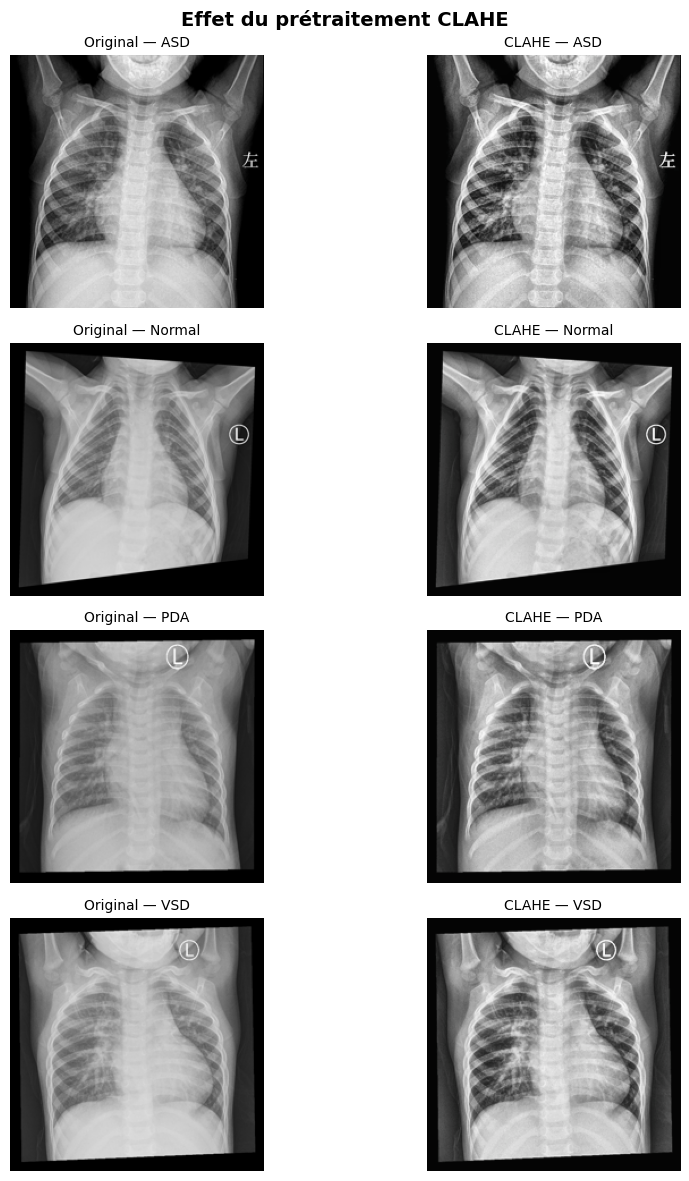

✅ CLAHE appliqué et visualisé !


In [ ]:
def apply_clahe(pil_image, clip_limit=2.0, tile_grid_size=(8, 8)):
    """
    Applique CLAHE sur une image PIL.
    Travaille sur le canal L (luminance) en espace LAB pour
    améliorer le contraste sans modifier les couleurs.

    Args:
        pil_image      : Image PIL en mode RGB
        clip_limit     : Limite de contraste (2.0 = bon équilibre bruit/contraste)
        tile_grid_size : Taille des tuiles locales (8x8 = standard)

    Returns:
        Image PIL améliorée en mode RGB
    """
    img_np  = np.array(pil_image)
    img_lab = cv2.cvtColor(img_np, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(img_lab)

    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid_size)
    l_eq  = clahe.apply(l)

    img_lab_eq = cv2.merge([l_eq, a, b])
    img_rgb_eq = cv2.cvtColor(img_lab_eq, cv2.COLOR_LAB2RGB)
    return Image.fromarray(img_rgb_eq)


# ── Visualiser l'effet de CLAHE sur quelques exemples ─────────────────────
sample_paths = []
for cls in ORIG_CLASSES:
    cls_dir = DATA_DIR / cls
    if cls_dir.exists():
        imgs = list(cls_dir.glob('*.jpg')) + list(cls_dir.glob('*.png'))
        if imgs:
            sample_paths.append((cls, imgs[0]))

n_samples = min(4, len(sample_paths))
fig, axes = plt.subplots(n_samples, 2, figsize=(10, 3 * n_samples))
fig.suptitle('Effet du prétraitement CLAHE', fontsize=14, fontweight='bold')

if n_samples == 1:
    axes = [axes]

for i, (cls_name, img_path) in enumerate(sample_paths[:n_samples]):
    original = Image.open(img_path).convert('RGB').resize((224, 224))
    enhanced = apply_clahe(original)

    axes[i][0].imshow(original)
    axes[i][0].set_title(f'Original — {cls_name}', fontsize=10)
    axes[i][0].axis('off')

    axes[i][1].imshow(enhanced)
    axes[i][1].set_title(f'CLAHE — {cls_name}', fontsize=10)
    axes[i][1].axis('off')

plt.tight_layout()
plt.show()
print('✅ CLAHE appliqué et visualisé !')


---
## 💾 Étape 3 — Téléchargement du dataset

In [ ]:
import kagglehub

path = kagglehub.competition_download('congenital-heart-disease')
print("📁 Chemin :", path)

# ── Détection automatique du dossier ──────────────────────────────────────
dataset_path  = Path(path)
ORIG_CLASSES  = ['ASD', 'Normal', 'PDA', 'VSD']

DATA_DIR = None
for folder in dataset_path.rglob('*'):
    if folder.is_dir():
        subs = [f.name for f in folder.iterdir() if f.is_dir()]
        if any(c in subs for c in ORIG_CLASSES):
            DATA_DIR = folder
            break
if DATA_DIR is None:
    DATA_DIR = dataset_path

print(f"✅ Dossier des données : {DATA_DIR}")

100%|██████████| 356M/356M [00:03<00:00, 111MB/s]

Extracting files...


📁 Chemin : /root/.cache/kagglehub/competitions/congenital-heart-disease
✅ Dossier des données : /root/.cache/kagglehub/competitions/congenital-heart-disease


---
## 🔍 Étape 4 — Exploration et visualisation du déséquilibre

On analyse la distribution **avant** et **après** le regroupement binaire.

In [ ]:
# ── Comptage par classe originale ─────────────────────────────────────────
print("📊 Distribution originale (4 classes) :")
orig_counts = {}
for cls in ORIG_CLASSES:
    cls_path = DATA_DIR / cls
    n = len(list(cls_path.glob('*.*'))) if cls_path.exists() else 0
    orig_counts[cls] = n
    print(f"   {cls:10s} : {n:>4} images")

# ── Distribution binaire ──────────────────────────────────────────────────
n_normal = orig_counts.get('Normal', 0)
n_malade = sum(orig_counts[c] for c in ['ASD', 'PDA', 'VSD'])
total    = n_normal + n_malade
ratio    = n_malade / n_normal

print(f"\n📊 Distribution binaire :")
print(f"   Normal  : {n_normal:>4} images  ({n_normal/total:.1%})")
print(f"   Malade  : {n_malade:>4} images  ({n_malade/total:.1%})")
print(f"   Total   : {total:>4} images")
print(f"   Ratio déséquilibre : 1 Normal pour {ratio:.1f} Malades")

📊 Distribution originale (4 classes) :
   ASD        :  194 images
   Normal     :  208 images
   PDA        :  216 images
   VSD        :  210 images

📊 Distribution binaire :
   Normal  :  208 images  (25.1%)
   Malade  :  620 images  (74.9%)
   Total   :  828 images
   Ratio déséquilibre : 1 Normal pour 3.0 Malades


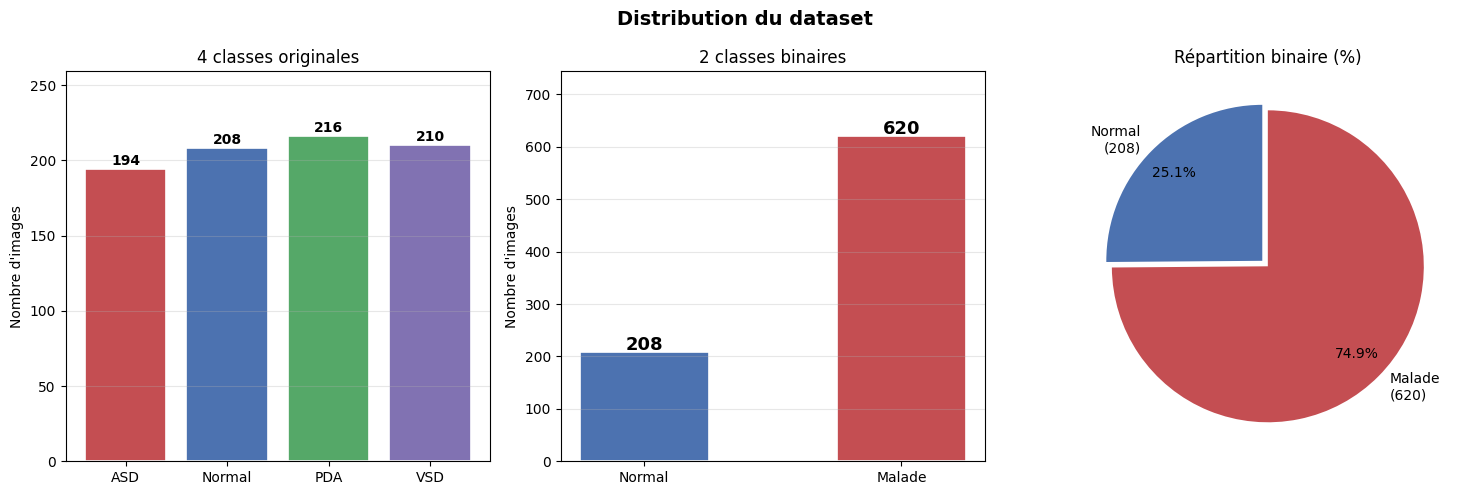


⚠️  Déséquilibre de 3.0x → nécessite Weighted Loss + WeightedRandomSampler


In [ ]:
# ── Visualisation du déséquilibre ─────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Distribution du dataset', fontsize=14, fontweight='bold')

# Distribution originale (4 classes)
colors_orig = ['#C44E52', '#4C72B0', '#55A868', '#8172B2']
bars = axes[0].bar(orig_counts.keys(), orig_counts.values(),
                   color=colors_orig, edgecolor='white', linewidth=1.2)
for bar, val in zip(bars, orig_counts.values()):
    axes[0].text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 3, str(val),
                 ha='center', fontweight='bold')
axes[0].set_title('4 classes originales')
axes[0].set_ylabel('Nombre d\'images')
axes[0].grid(axis='y', alpha=0.3)
axes[0].set_ylim(0, max(orig_counts.values()) * 1.2)

# Distribution binaire
colors_bin = ['#4C72B0', '#C44E52']
bars2 = axes[1].bar(CLASS_NAMES, [n_normal, n_malade],
                    color=colors_bin, edgecolor='white', linewidth=1.2, width=0.5)
for bar, val in zip(bars2, [n_normal, n_malade]):
    axes[1].text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 5, str(val),
                 ha='center', fontsize=13, fontweight='bold')
axes[1].set_title('2 classes binaires')
axes[1].set_ylabel('Nombre d\'images')
axes[1].grid(axis='y', alpha=0.3)
axes[1].set_ylim(0, max(n_normal, n_malade) * 1.2)

# Camembert
axes[2].pie(
    [n_normal, n_malade],
    labels=[f'Normal\n({n_normal})', f'Malade\n({n_malade})'],
    colors=colors_bin,
    autopct='%1.1f%%',
    startangle=90,
    explode=(0.05, 0),
    pctdistance=0.8
)
axes[2].set_title('Répartition binaire (%)')

plt.tight_layout()
plt.show()

print(f"\n⚠️  Déséquilibre de {ratio:.1f}x → nécessite Weighted Loss + WeightedRandomSampler")

---
## 🗄️ Étape 5 — Dataset binaire personnalisé

On crée un `Dataset` PyTorch qui :
- Collecte **toutes** les images des 4 dossiers
- Mappe chaque image vers sa classe binaire (0=Normal, 1=Malade)
- Accepte une transformation paramétrable (train ou val)

Cela remplace `ImageFolder` qui ne peut pas gérer le regroupement de classes.

In [ ]:
class BinaryHeartDataset(Dataset):
    """
    Dataset binaire pour la classification Normal vs Malade.
    Intègre le prétraitement CLAHE avant les transformations PyTorch.

    Regroupe ASD + PDA + VSD → Malade (label=1)
    Garde Normal → Normal (label=0)

    Args:
        data_dir    : dossier racine contenant ASD/, Normal/, PDA/, VSD/
        binary_map  : dict {nom_classe: label_binaire}
        transform   : transformations torchvision à appliquer
        use_clahe   : bool, applique CLAHE si True (défaut=True)
        clip_limit  : paramètre CLAHE (défaut=2.0)
    """

    def __init__(self, data_dir, binary_map, transform=None,
                 use_clahe=True, clip_limit=2.0):
        self.transform  = transform
        self.use_clahe  = use_clahe
        self.clip_limit = clip_limit
        self.samples    = []

        for cls_name, binary_label in binary_map.items():
            cls_path = Path(data_dir) / cls_name
            if not cls_path.exists():
                print(f'⚠️  Dossier non trouvé : {cls_path}')
                continue
            for ext in ('*.jpg', '*.jpeg', '*.png', '*.bmp', '*.tiff'):
                for img_path in cls_path.glob(ext):
                    self.samples.append((str(img_path), binary_label))

        self.targets = [s[1] for s in self.samples]

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        image = Image.open(img_path).convert('RGB')

        # ── Prétraitement CLAHE ───────────────────────────────────────────
        if self.use_clahe:
            image = apply_clahe(image, clip_limit=self.clip_limit)

        if self.transform:
            image = self.transform(image)
        return image, label


# ── Vérification ──────────────────────────────────────────────────────────
temp_dataset = BinaryHeartDataset(DATA_DIR, BINARY_MAP, use_clahe=True)
labels_array = np.array(temp_dataset.targets)

print('✅ BinaryHeartDataset avec CLAHE créé !')
print(f'   Total images : {len(temp_dataset)}')
print(f'   Normal (0)   : {(labels_array == 0).sum()}')
print(f'   Malade (1)   : {(labels_array == 1).sum()}')
print(f'   CLAHE        : ✅ Activé (clip_limit=2.0)')
del temp_dataset


✅ BinaryHeartDataset avec CLAHE créé !
   Total images : 828
   Normal (0)   : 208
   Malade (1)   : 620
   CLAHE        : ✅ Activé (clip_limit=2.0)


---
## 🔄 Étape 6 — Transformations

In [ ]:
# ── Transformations d'entraînement ────────────────────────────────────────
train_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.RandomAffine(
        degrees=10,
        translate=(0.05, 0.05),
        scale=(0.95, 1.05)
    ),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.RandomApply([
        transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 0.3))
    ], p=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

# ── Transformations de validation / test ──────────────────────────────────
val_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

print("✅ Transformations définies !")

✅ Transformations définies !


---
## 🗂️ Étape 7 — Split et DataLoaders

### WeightedRandomSampler
Au lieu de piocher les images au hasard dans chaque batch,
le sampler **augmente la probabilité** de sélectionner les images Normal
pour que chaque batch soit proche de 50/50.

Chaque image reçoit un poids `w_i = 1 / count(sa_classe)` :
- Images Normal → poids élevé (classe rare)
- Images Malade → poids faible (classe fréquente)

In [ ]:
# ── Créer les datasets avec les bonnes transformations ────────────────────
train_dataset = BinaryHeartDataset(DATA_DIR, BINARY_MAP, transform=train_transforms)
val_dataset   = BinaryHeartDataset(DATA_DIR, BINARY_MAP, transform=val_transforms)
test_dataset  = BinaryHeartDataset(DATA_DIR, BINARY_MAP, transform=val_transforms)

total   = len(train_dataset)
n_train = int(0.80 * total)
n_val   = int(0.10 * total)
n_test  = total - n_train - n_val

# Générer les indices du split (reproductible)
indices     = torch.randperm(total, generator=torch.Generator().manual_seed(SEED)).tolist()
train_idx   = indices[:n_train]
val_idx     = indices[n_train:n_train + n_val]
test_idx    = indices[n_train + n_val:]

# Sous-ensembles
from torch.utils.data import Subset
train_subset = Subset(train_dataset, train_idx)
val_subset   = Subset(val_dataset,   val_idx)
test_subset  = Subset(test_dataset,  test_idx)

print(f"✂️  Répartition (80/10/10) :")
print(f"   Entraînement : {len(train_subset)} images")
print(f"   Validation   : {len(val_subset)} images")
print(f"   Test         : {len(test_subset)} images")

# ── Labels du train pour les poids ────────────────────────────────────────
train_labels  = np.array(train_dataset.targets)[train_idx]
class_counts  = np.bincount(train_labels)   # [n_Normal, n_Malade]

print(f"\n   Train — Normal : {class_counts[0]} | Malade : {class_counts[1]}")

# ── WeightedRandomSampler ─────────────────────────────────────────────────
# Poids par classe : inverse de la fréquence
class_weights_sampler = 1.0 / class_counts
# Attribuer le poids de sa classe à chaque image
sample_weights = torch.tensor(
    [class_weights_sampler[label] for label in train_labels],
    dtype=torch.float32
)
sampler = WeightedRandomSampler(
    weights     = sample_weights,
    num_samples = len(sample_weights),
    replacement = True   # Autorise le re-tirage (nécessaire pour sur-représenter Normal)
)

# ── DataLoaders ───────────────────────────────────────────────────────────
train_loader = DataLoader(
    train_subset,
    batch_size = BATCH_SIZE,
    sampler    = sampler,      # WeightedRandomSampler (pas shuffle)
    num_workers= 2
)
val_loader = DataLoader(
    val_subset,
    batch_size  = BATCH_SIZE,
    shuffle     = False,
    num_workers = 2
)
test_loader = DataLoader(
    test_subset,
    batch_size  = BATCH_SIZE,
    shuffle     = False,
    num_workers = 2
)

print(f"\n✅ DataLoaders créés !")
print(f"   Train   : {len(train_loader)} batches  (avec WeightedRandomSampler)")
print(f"   Val     : {len(val_loader)} batches")
print(f"   Test    : {len(test_loader)} batches")

✂️  Répartition (80/10/10) :
   Entraînement : 662 images
   Validation   : 82 images
   Test         : 84 images

   Train — Normal : 168 | Malade : 494

✅ DataLoaders créés !
   Train   : 42 batches  (avec WeightedRandomSampler)
   Val     : 6 batches
   Test    : 6 batches


In [ ]:
# ── Vérifier l'équilibre du sampler sur quelques batches ──────────────────
print("📊 Vérification du WeightedRandomSampler (10 premiers batches) :")
normal_counts_batches, malade_counts_batches = [], []

for i, (_, labels) in enumerate(train_loader):
    if i >= 10:
        break
    normal_counts_batches.append((labels == 0).sum().item())
    malade_counts_batches.append((labels == 1).sum().item())

print(f"   Normal  moyen par batch : {np.mean(normal_counts_batches):.1f} "
      f"({np.mean(normal_counts_batches)/BATCH_SIZE:.0%})")
print(f"   Malade  moyen par batch : {np.mean(malade_counts_batches):.1f} "
      f"({np.mean(malade_counts_batches)/BATCH_SIZE:.0%})")
print("   (Idéal : proche de 50/50 grâce au sampler)")

📊 Vérification du WeightedRandomSampler (10 premiers batches) :
   Normal  moyen par batch : 7.4 (46%)
   Malade  moyen par batch : 8.6 (54%)
   (Idéal : proche de 50/50 grâce au sampler)


---
## ⚖️ Étape 8 — Weighted Loss

En plus du sampler, la loss applique un **poids plus élevé** aux erreurs sur Normal.
Double protection contre le déséquilibre.

In [ ]:
# Poids pour la loss : inverse de la fréquence, normalisés
weights_loss = 1.0 / class_counts
weights_loss = weights_loss / weights_loss.sum() * NUM_CLASSES
weights_loss = torch.tensor(weights_loss, dtype=torch.float32).to(device)

criterion = nn.CrossEntropyLoss(
    weight        = weights_loss,
    label_smoothing = 0.1
)

print("✅ Weighted Loss configurée !")
print(f"\n   Classe  | Nb images (train) | Poids loss")
print(f"   --------|-------------------|----------")
for i, (cls, cnt, w) in enumerate(
        zip(CLASS_NAMES, class_counts, weights_loss.cpu())):
    print(f"   {cls:7s} | {cnt:>17} | {w.item():.4f}")

✅ Weighted Loss configurée !

   Classe  | Nb images (train) | Poids loss
   --------|-------------------|----------
   Normal  |               168 | 1.4924
   Malade  |               494 | 0.5076


---
## 🧠 Étape 9a — Modèle CNN Personnalisé (Baseline)

Avant d'utiliser ResNet18 (transfer learning), on entraîne un **CNN from scratch** pour avoir une baseline de comparaison.

Architecture CNN :
- 4 blocs convolutifs : Conv → BN → ReLU → MaxPool
- Filtres : 32 → 64 → 128 → 256
- Dropout spatial (0.25) après chaque bloc
- Tête de classification : FC(1024) → Dropout(0.5) → FC(2)

> 💡 Ce modèle sert de **référence** : si ResNet18 ne fait pas mieux, c'est un signal de problème.


In [ ]:
class CNNBinaire(nn.Module):
    """
    CNN personnalisé pour la classification binaire Normal vs Malade.
    Entraîné from scratch avec les images prétraitées CLAHE.

    Architecture :
        Bloc 1 : Conv(3→32)  + BN + ReLU + MaxPool + Dropout2d
        Bloc 2 : Conv(32→64) + BN + ReLU + MaxPool + Dropout2d
        Bloc 3 : Conv(64→128)+ BN + ReLU + MaxPool + Dropout2d
        Bloc 4 : Conv(128→256)+BN + ReLU + MaxPool + Dropout2d
        Tête   : AdaptiveAvgPool → FC(1024) → Dropout(0.5) → FC(2)
    """

    def __init__(self, num_classes=2, dropout=0.25):
        super(CNNBinaire, self).__init__()

        def conv_block(in_ch, out_ch):
            return nn.Sequential(
                nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(2, 2),
                nn.Dropout2d(p=dropout)
            )

        self.features = nn.Sequential(
            conv_block(3,   32),   # 224 → 112
            conv_block(32,  64),   # 112 →  56
            conv_block(64,  128),  #  56 →  28
            conv_block(128, 256),  #  28 →  14
        )
        self.pool = nn.AdaptiveAvgPool2d((4, 4))  # → 256 × 4 × 4 = 4096

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 4 * 4, 1024),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.5),
            nn.Linear(1024, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = self.classifier(x)
        return x


# ── Instancier et vérifier ────────────────────────────────────────────────
cnn_model = CNNBinaire(num_classes=NUM_CLASSES).to(device)

total_cnn     = sum(p.numel() for p in cnn_model.parameters())
train_cnn     = sum(p.numel() for p in cnn_model.parameters() if p.requires_grad)

with torch.no_grad():
    test_out = cnn_model(torch.randn(2, 3, IMG_SIZE, IMG_SIZE).to(device))

print('✅ CNNBinaire instancié !')
print(f'   Paramètres totaux  : {total_cnn:>10,}')
print(f'   Tous entraînables  : {train_cnn:>10,}  (from scratch)')
print(f'   Sortie             : {test_out.shape}  → 2 logits (Normal, Malade)')


✅ CNNBinaire instancié !
   Paramètres totaux  :  4,586,274
   Tous entraînables  :  4,586,274  (from scratch)
   Sortie             : torch.Size([2, 2])  → 2 logits (Normal, Malade)


---
## 🚀 Étape 9b — Entraînement du CNN

On utilise les mêmes DataLoaders, Loss et Early Stopping que pour ResNet18.
Le CNN utilise un learning rate légèrement plus élevé car il part de zéro.


In [ ]:
# ── Config CNN ───────────────────────────────────────────────────────────
LR_CNN          = 1e-3
NUM_EPOCHS_CNN  = 40
PATIENCE_CNN    = 7
SAVE_CNN        = 'best_model_cnn.pth'

optimizer_cnn = optim.AdamW(
    cnn_model.parameters(),
    lr=LR_CNN, weight_decay=1e-4
)
scheduler_cnn = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_cnn, mode='min', patience=3, factor=0.5
)

history_cnn = {
    'train_loss': [], 'val_loss': [],
    'train_acc' : [], 'val_acc' : []
}

best_val_loss_cnn = float('inf')
best_val_acc_cnn  = 0.0
es_counter_cnn    = 0

print(f'🚀 Entraînement CNN (max {NUM_EPOCHS_CNN} époques)\n')
print(f'{"Époque":>6} | {"Train Loss":>10} | {"Train Acc":>9} | '
      f'{"Val Loss":>9} | {"Val Acc":>8} | {"ES":>6}')
print('─' * 70)

for epoch in range(1, NUM_EPOCHS_CNN + 1):

    # Entraînement
    cnn_model.train()
    t_loss, t_correct = 0.0, 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer_cnn.zero_grad()
        outputs = cnn_model(images)
        loss    = criterion(outputs, labels)
        loss.backward()
        nn.utils.clip_grad_norm_(cnn_model.parameters(), max_norm=1.0)
        optimizer_cnn.step()
        t_loss    += loss.item() * images.size(0)
        t_correct += (outputs.argmax(1) == labels).sum().item()
    t_loss /= len(train_subset)
    t_acc   = t_correct / len(train_subset)

    # Validation
    cnn_model.eval()
    v_loss, v_correct = 0.0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs    = cnn_model(images)
            loss       = criterion(outputs, labels)
            v_loss    += loss.item() * images.size(0)
            v_correct += (outputs.argmax(1) == labels).sum().item()
    v_loss /= len(val_subset)
    v_acc   = v_correct / len(val_subset)

    scheduler_cnn.step(v_loss)

    if v_loss < best_val_loss_cnn:
        best_val_loss_cnn = v_loss
        best_val_acc_cnn  = v_acc
        es_counter_cnn    = 0
        torch.save(cnn_model.state_dict(), SAVE_CNN)
        flag = '⭐'
    else:
        es_counter_cnn += 1
        flag = f'{es_counter_cnn}/{PATIENCE_CNN}'

    history_cnn['train_loss'].append(t_loss)
    history_cnn['val_loss'  ].append(v_loss)
    history_cnn['train_acc' ].append(t_acc)
    history_cnn['val_acc'   ].append(v_acc)

    print(f'{epoch:>6} | {t_loss:>10.4f} | {t_acc:>8.2%} | '
          f'{v_loss:>9.4f} | {v_acc:>7.2%} | {flag}')

    if es_counter_cnn >= PATIENCE_CNN:
        print(f'\n🛑 Early Stopping CNN à l\'époque {epoch}.')
        break

print(f'\n✅ Entraînement CNN terminé !')
print(f'   Meilleure Val Loss : {best_val_loss_cnn:.4f}')
print(f'   Meilleure Val Acc  : {best_val_acc_cnn:.2%}')


🚀 Entraînement CNN (max 40 époques)

Époque | Train Loss | Train Acc |  Val Loss |  Val Acc |     ES
──────────────────────────────────────────────────────────────────────
     1 |     1.1877 |   52.11% |    0.8506 |  26.83% | ⭐
     2 |     0.7475 |   56.04% |    0.9990 |  26.83% | 1/7
     3 |     0.6138 |   54.53% |    1.0309 |  26.83% | 2/7
     4 |     0.5842 |   54.83% |    0.7580 |  26.83% | ⭐
     5 |     0.5735 |   53.02% |    0.6837 |  32.93% | ⭐
     6 |     0.5623 |   53.17% |    0.8348 |  26.83% | 1/7
     7 |     0.5576 |   56.65% |    0.6469 |  45.12% | ⭐
     8 |     0.5731 |   53.93% |    0.7803 |  26.83% | 1/7
     9 |     0.5560 |   54.68% |    0.6423 |  52.44% | ⭐
    10 |     0.5367 |   59.82% |    0.7675 |  30.49% | 1/7
    11 |     0.5943 |   53.02% |    0.6477 |  46.34% | 2/7
    12 |     0.5243 |   61.78% |    0.6480 |  51.22% | 3/7
    13 |     0.5699 |   55.29% |    0.6452 |  47.56% | 4/7
    14 |     0.5337 |   54.98% |    0.6164 |  53.66% | ⭐
    15 |     0

---
## 🧪 Étape 9c — Évaluation du CNN sur le set de test


In [ ]:
# ── Charger le meilleur CNN ──────────────────────────────────────────────
cnn_model.load_state_dict(torch.load(SAVE_CNN, map_location=device))
cnn_model.eval()

cnn_preds, cnn_labels, cnn_probs = [], [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = cnn_model(images)
        probs   = torch.softmax(outputs, dim=1)[:, 1].cpu().numpy()
        preds   = outputs.argmax(dim=1).cpu().numpy()
        cnn_preds.extend(preds)
        cnn_labels.extend(labels.numpy())
        cnn_probs.extend(probs)

cnn_preds  = np.array(cnn_preds)
cnn_labels = np.array(cnn_labels)
cnn_probs  = np.array(cnn_probs)

cnn_accuracy  = (cnn_preds == cnn_labels).mean()
cnn_precision = precision_score(cnn_labels, cnn_preds, zero_division=0)
cnn_recall    = recall_score(cnn_labels, cnn_preds, zero_division=0)
cnn_f1        = f1_score(cnn_labels, cnn_preds, zero_division=0)
cnn_roc_auc   = roc_auc_score(cnn_labels, cnn_probs)

# Stocker pour la comparaison finale
results_cnn = {
    'accuracy' : cnn_accuracy,
    'precision': cnn_precision,
    'recall'   : cnn_recall,
    'f1'       : cnn_f1,
    'roc_auc'  : cnn_roc_auc,
    'history'  : history_cnn,
    'preds'    : cnn_preds,
    'labels'   : cnn_labels,
    'probs'    : cnn_probs,
}

print('═' * 50)
print('  📊 RÉSULTATS CNN SUR LE SET DE TEST')
print('═' * 50)
print(f'  Accuracy   : {cnn_accuracy:.2%}')
print(f'  Precision  : {cnn_precision:.2%}')
print(f'  Recall     : {cnn_recall:.2%}')
print(f'  F1-score   : {cnn_f1:.2%}')
print(f'  ROC-AUC    : {cnn_roc_auc:.4f}')
print('═' * 50)
print('\n📋 Rapport de classification CNN :')
print(classification_report(cnn_labels, cnn_preds, target_names=CLASS_NAMES))


══════════════════════════════════════════════════
  📊 RÉSULTATS CNN SUR LE SET DE TEST
══════════════════════════════════════════════════
  Accuracy   : 54.76%
  Precision  : 96.67%
  Recall     : 43.94%
  F1-score   : 60.42%
  ROC-AUC    : 0.7685
══════════════════════════════════════════════════

📋 Rapport de classification CNN :
              precision    recall  f1-score   support

      Normal       0.31      0.94      0.47        18
      Malade       0.97      0.44      0.60        66

    accuracy                           0.55        84
   macro avg       0.64      0.69      0.54        84
weighted avg       0.83      0.55      0.58        84



---
## 🧠 Étape 9 — Modèle ResNet18

Configuration :
- Toutes les couches gelées sauf `layer4` et `fc`
- Couche finale : `Dropout(0.5) → Linear(512 → 2)`
- Sortie : 2 logits (Normal, Malade)

In [ ]:
# ── Charger ResNet18 pré-entraîné ─────────────────────────────────────────
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# ── Geler toutes les couches ──────────────────────────────────────────────
for param in model.parameters():
    param.requires_grad = False

# ── Dégeler layer4 ────────────────────────────────────────────────────────
for param in model.layer4.parameters():
    param.requires_grad = True

# ── Remplacer la couche finale (512 → 2 classes binaires) ─────────────────
model.fc = nn.Sequential(
    nn.Dropout(p=0.5),
    nn.Linear(model.fc.in_features, NUM_CLASSES)   # 512 → 2
)
# fc est entraînable par défaut (nouveau module)

model = model.to(device)

# ── Résumé ────────────────────────────────────────────────────────────────
total_p     = sum(p.numel() for p in model.parameters())
trainable_p = sum(p.numel() for p in model.parameters() if p.requires_grad)
frozen_p    = total_p - trainable_p

with torch.no_grad():
    out = model(torch.randn(2, 3, IMG_SIZE, IMG_SIZE).to(device))

print("✅ ResNet18 configuré (classification binaire) !")
print(f"\n   Paramètres totaux   : {total_p:>10,}")
print(f"   Backbone gelé       : {frozen_p:>10,}  (conv1 → layer3)")
print(f"   Entraînables        : {trainable_p:>10,}  (layer4 + fc)")
print(f"   Sortie              : {out.shape}  → 2 logits (Normal, Malade)")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:01<00:00, 45.3MB/s]


✅ ResNet18 configuré (classification binaire) !

   Paramètres totaux   : 11,177,538
   Backbone gelé       :  2,782,784  (conv1 → layer3)
   Entraînables        :  8,394,754  (layer4 + fc)
   Sortie              : torch.Size([2, 2])  → 2 logits (Normal, Malade)


---
## ⚙️ Étape 10 — Optimiseur et Scheduler

In [ ]:
# Hyperparamètres
LEARNING_RATE = 1e-5
WEIGHT_DECAY  = 1e-5
NUM_EPOCHS    = 40
PATIENCE      = 7
SAVE_PATH     = 'best_model_binary.pth'

# AdamW : uniquement les paramètres entraînables
optimizer = optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr           = LEARNING_RATE,
    weight_decay = WEIGHT_DECAY
)

# ReduceLROnPlateau : divise le LR par 2 si val_loss stagne
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode    = 'min',
    patience= 3,
    factor  = 0.5,

)

print("✅ Configuration d'entraînement :")
print(f"   Optimiseur    : AdamW (lr={LEARNING_RATE}, wd={WEIGHT_DECAY})")
print(f"   Scheduler     : ReduceLROnPlateau (patience=3, factor=0.5)")
print(f"   Loss          : Weighted CrossEntropyLoss + LabelSmoothing(0.1)")
print(f"   Max époques   : {NUM_EPOCHS} (Early Stopping patience={PATIENCE})")

✅ Configuration d'entraînement :
   Optimiseur    : AdamW (lr=1e-05, wd=1e-05)
   Scheduler     : ReduceLROnPlateau (patience=3, factor=0.5)
   Loss          : Weighted CrossEntropyLoss + LabelSmoothing(0.1)
   Max époques   : 40 (Early Stopping patience=7)


---
## 🚀 Étape 11 — Entraînement avec Early Stopping

In [ ]:
history = {
    'train_loss': [], 'val_loss': [],
    'train_acc' : [], 'val_acc' : []
}

best_val_loss = float('inf')
best_val_acc  = 0.0
es_counter    = 0

print(f"🚀 Entraînement — Classification Binaire (max {NUM_EPOCHS} époques)\n")
print(f"{'Époque':>6} | {'Train Loss':>10} | {'Train Acc':>9} | "
      f"{'Val Loss':>9} | {'Val Acc':>8} | {'ES':>6}")
print("─" * 70)

for epoch in range(1, NUM_EPOCHS + 1):

    # ── Entraînement ──────────────────────────────────────────────────────
    model.train()
    t_loss, t_correct = 0.0, 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss    = criterion(outputs, labels)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        t_loss    += loss.item() * images.size(0)
        t_correct += (outputs.argmax(1) == labels).sum().item()

    t_loss /= len(train_subset)
    t_acc   = t_correct / len(train_subset)

    # ── Validation ────────────────────────────────────────────────────────
    model.eval()
    v_loss, v_correct = 0.0, 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs    = model(images)
            loss       = criterion(outputs, labels)
            v_loss    += loss.item() * images.size(0)
            v_correct += (outputs.argmax(1) == labels).sum().item()

    v_loss /= len(val_subset)
    v_acc   = v_correct / len(val_subset)

    scheduler.step(v_loss)

    # ── Early Stopping ────────────────────────────────────────────────────
    if v_loss < best_val_loss:
        best_val_loss = v_loss
        best_val_acc  = v_acc
        es_counter    = 0
        torch.save(model.state_dict(), SAVE_PATH)
        flag = "⭐"
    else:
        es_counter += 1
        flag = f"{es_counter}/{PATIENCE}"

    history['train_loss'].append(t_loss)
    history['val_loss'  ].append(v_loss)
    history['train_acc' ].append(t_acc)
    history['val_acc'   ].append(v_acc)

    print(f"{epoch:>6} | {t_loss:>10.4f} | {t_acc:>8.2%} | "
          f"{v_loss:>9.4f} | {v_acc:>7.2%} | {flag}")

    if es_counter >= PATIENCE:
        print(f"\n🛑 Early Stopping à l'époque {epoch}.")
        break

print(f"\n✅ Entraînement terminé !")
print(f"   Meilleure Val Loss : {best_val_loss:.4f}")
print(f"   Meilleure Val Acc  : {best_val_acc:.2%}")

🚀 Entraînement — Classification Binaire (max 40 époques)

Époque | Train Loss | Train Acc |  Val Loss |  Val Acc |     ES
──────────────────────────────────────────────────────────────────────
     1 |     0.2498 |   93.50% |    0.4622 |  84.15% | ⭐
     2 |     0.2601 |   93.50% |    0.4475 |  86.59% | ⭐
     3 |     0.2723 |   92.90% |    0.4617 |  85.37% | 1/7
     4 |     0.2417 |   95.32% |    0.4738 |  85.37% | 2/7
     5 |     0.2679 |   94.86% |    0.4585 |  85.37% | 3/7
     6 |     0.2393 |   95.02% |    0.4621 |  86.59% | 4/7
     7 |     0.2582 |   93.66% |    0.4667 |  86.59% | 5/7
     8 |     0.2629 |   92.15% |    0.4643 |  85.37% | 6/7
     9 |     0.2687 |   92.60% |    0.4550 |  85.37% | 7/7

🛑 Early Stopping à l'époque 9.

✅ Entraînement terminé !
   Meilleure Val Loss : 0.4475
   Meilleure Val Acc  : 86.59%


---
## 📈 Étape 12 — Courbes d'apprentissage

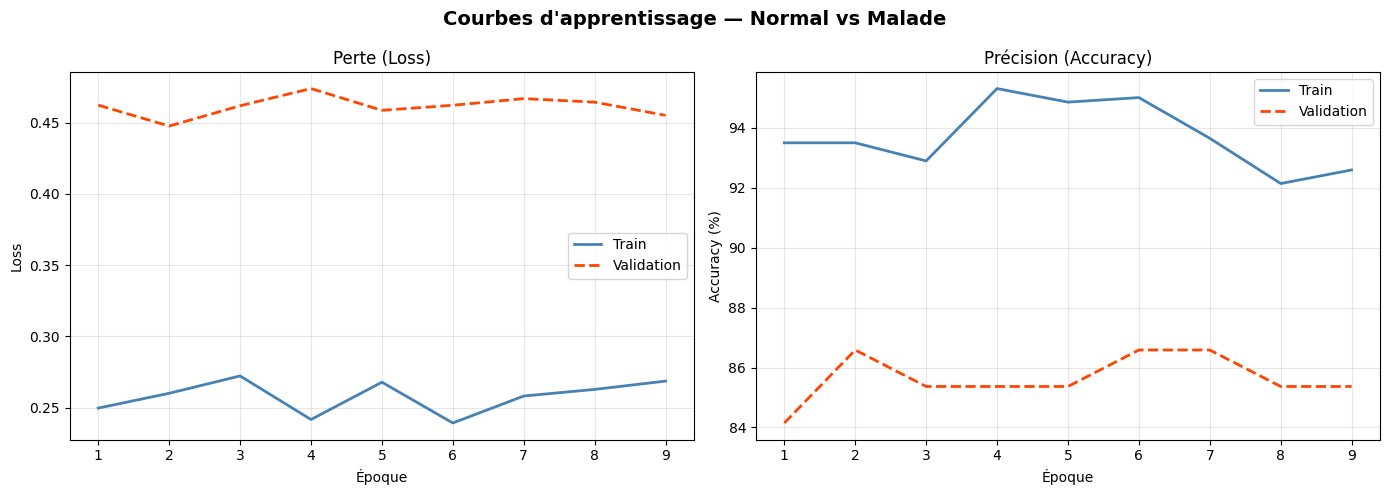

In [ ]:
epochs_range = range(1, len(history['train_loss']) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Courbes d\'apprentissage — Normal vs Malade',
             fontsize=14, fontweight='bold')

ax1.plot(epochs_range, history['train_loss'],
         label='Train', color='steelblue', linewidth=2)
ax1.plot(epochs_range, history['val_loss'],
         label='Validation', color='orangered', linewidth=2, linestyle='--')
ax1.set_title('Perte (Loss)')
ax1.set_xlabel('Époque')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(epochs_range, [a * 100 for a in history['train_acc']],
         label='Train', color='steelblue', linewidth=2)
ax2.plot(epochs_range, [a * 100 for a in history['val_acc']],
         label='Validation', color='orangered', linewidth=2, linestyle='--')
ax2.set_title('Précision (Accuracy)')
ax2.set_xlabel('Époque')
ax2.set_ylabel('Accuracy (%)')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## 🧪 Étape 13 — Évaluation complète sur le set de test

Pour la classification binaire, l'accuracy seule n'est pas suffisante
car le dataset est déséquilibré. On utilise :

- **Precision** : parmi les prédictions Malade, combien sont vraiment Malades ?
- **Recall** : parmi les vrais Malades, combien le modèle a-t-il trouvés ?
- **F1-score** : moyenne harmonique Precision/Recall (métrique principale)
- **ROC-AUC** : capacité de discrimination globale du modèle (0.5 = aléatoire, 1.0 = parfait)

In [ ]:
# ── Charger le meilleur modèle ────────────────────────────────────────────
model.load_state_dict(torch.load(SAVE_PATH, map_location=device))
model.eval()

all_preds  = []
all_labels = []
all_probs  = []   # Probabilités pour le calcul ROC-AUC

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        probs   = torch.softmax(outputs, dim=1)[:, 1].cpu().numpy()  # Proba classe Malade
        preds   = outputs.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())
        all_probs.extend(probs)

all_preds  = np.array(all_preds)
all_labels = np.array(all_labels)
all_probs  = np.array(all_probs)

# ── Métriques ─────────────────────────────────────────────────────────────
accuracy  = (all_preds == all_labels).mean()
precision = precision_score(all_labels, all_preds, zero_division=0)
recall    = recall_score(all_labels, all_preds, zero_division=0)
f1        = f1_score(all_labels, all_preds, zero_division=0)
roc_auc   = roc_auc_score(all_labels, all_probs)

print("═" * 50)
print("  📊 RÉSULTATS SUR LE SET DE TEST")
print("═" * 50)
print(f"  Accuracy   : {accuracy:.2%}")
print(f"  Precision  : {precision:.2%}")
print(f"  Recall     : {recall:.2%}")
print(f"  F1-score   : {f1:.2%}")
print(f"  ROC-AUC    : {roc_auc:.4f}")
print("═" * 50)

print("\n📋 Rapport de classification détaillé :")
print(classification_report(all_labels, all_preds, target_names=CLASS_NAMES))

══════════════════════════════════════════════════
  📊 RÉSULTATS SUR LE SET DE TEST
══════════════════════════════════════════════════
  Accuracy   : 83.33%
  Precision  : 93.33%
  Recall     : 84.85%
  F1-score   : 88.89%
  ROC-AUC    : 0.9369
══════════════════════════════════════════════════

📋 Rapport de classification détaillé :
              precision    recall  f1-score   support

      Normal       0.58      0.78      0.67        18
      Malade       0.93      0.85      0.89        66

    accuracy                           0.83        84
   macro avg       0.76      0.81      0.78        84
weighted avg       0.86      0.83      0.84        84



---
## 🗂️ Étape 14 — Matrice de confusion + Courbe ROC

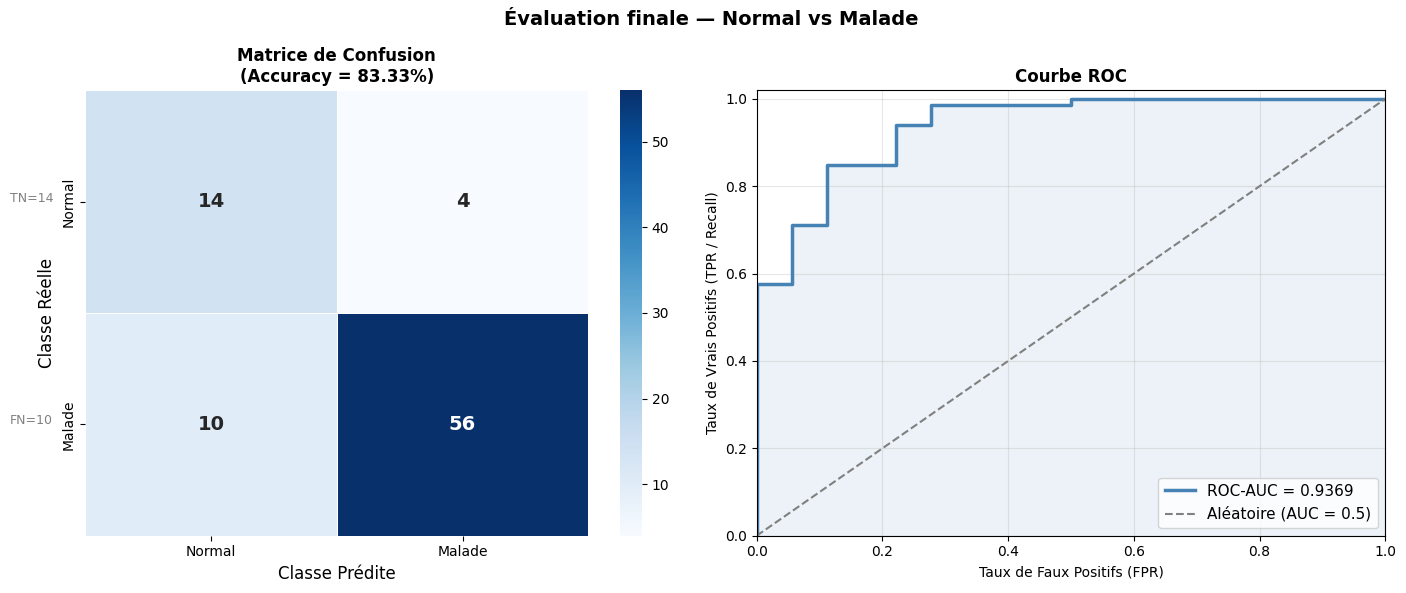


📖 Lecture de la matrice de confusion :
   TN =  14  : Normaux correctement détectés
   FP =   4  : Normaux incorrectement classés comme Malades
   FN =  10  : Malades non détectés  ← ⚠️  Erreurs critiques
   TP =  56  : Malades correctement détectés


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Évaluation finale — Normal vs Malade',
             fontsize=14, fontweight='bold')

# ── Matrice de confusion ──────────────────────────────────────────────────
cm = confusion_matrix(all_labels, all_preds)
sns.heatmap(
    cm,
    annot       = True,
    fmt         = 'd',
    cmap        = 'Blues',
    xticklabels = CLASS_NAMES,
    yticklabels = CLASS_NAMES,
    linewidths  = 0.5,
    ax          = axes[0],
    annot_kws   = {'size': 14, 'weight': 'bold'}
)
axes[0].set_title(f'Matrice de Confusion\n(Accuracy = {accuracy:.2%})',
                  fontweight='bold')
axes[0].set_xlabel('Classe Prédite',  fontsize=12)
axes[0].set_ylabel('Classe Réelle',   fontsize=12)

# Annoter TP, TN, FP, FN
tn, fp, fn, tp = cm.ravel()
axes[0].text(-0.3, 0.5, f'TN={tn}', fontsize=9, color='gray')
axes[0].text(-0.3, 1.5, f'FN={fn}', fontsize=9, color='gray')

# ── Courbe ROC ────────────────────────────────────────────────────────────
fpr, tpr, _ = roc_curve(all_labels, all_probs)

axes[1].plot(fpr, tpr,
             color='steelblue', linewidth=2.5,
             label=f'ROC-AUC = {roc_auc:.4f}')
axes[1].plot([0, 1], [0, 1],
             color='gray', linestyle='--', linewidth=1.5,
             label='Aléatoire (AUC = 0.5)')
axes[1].fill_between(fpr, tpr, alpha=0.1, color='steelblue')
axes[1].set_title('Courbe ROC', fontweight='bold')
axes[1].set_xlabel('Taux de Faux Positifs (FPR)')
axes[1].set_ylabel('Taux de Vrais Positifs (TPR / Recall)')
axes[1].legend(loc='lower right', fontsize=11)
axes[1].grid(True, alpha=0.3)
axes[1].set_xlim([0, 1])
axes[1].set_ylim([0, 1.02])

plt.tight_layout()
plt.show()

# Explication de la matrice de confusion
print(f"\n📖 Lecture de la matrice de confusion :")
print(f"   TN = {tn:>3}  : Normaux correctement détectés")
print(f"   FP = {fp:>3}  : Normaux incorrectement classés comme Malades")
print(f"   FN = {fn:>3}  : Malades non détectés  ← ⚠️  Erreurs critiques")
print(f"   TP = {tp:>3}  : Malades correctement détectés")

---
## 🖼️ Étape 15 — Visualisation des prédictions

On affiche les images de test avec :
- Le label réel
- La prédiction du modèle
- La probabilité d'être Malade
- ✅ Vert = correct | ❌ Rouge = incorrect

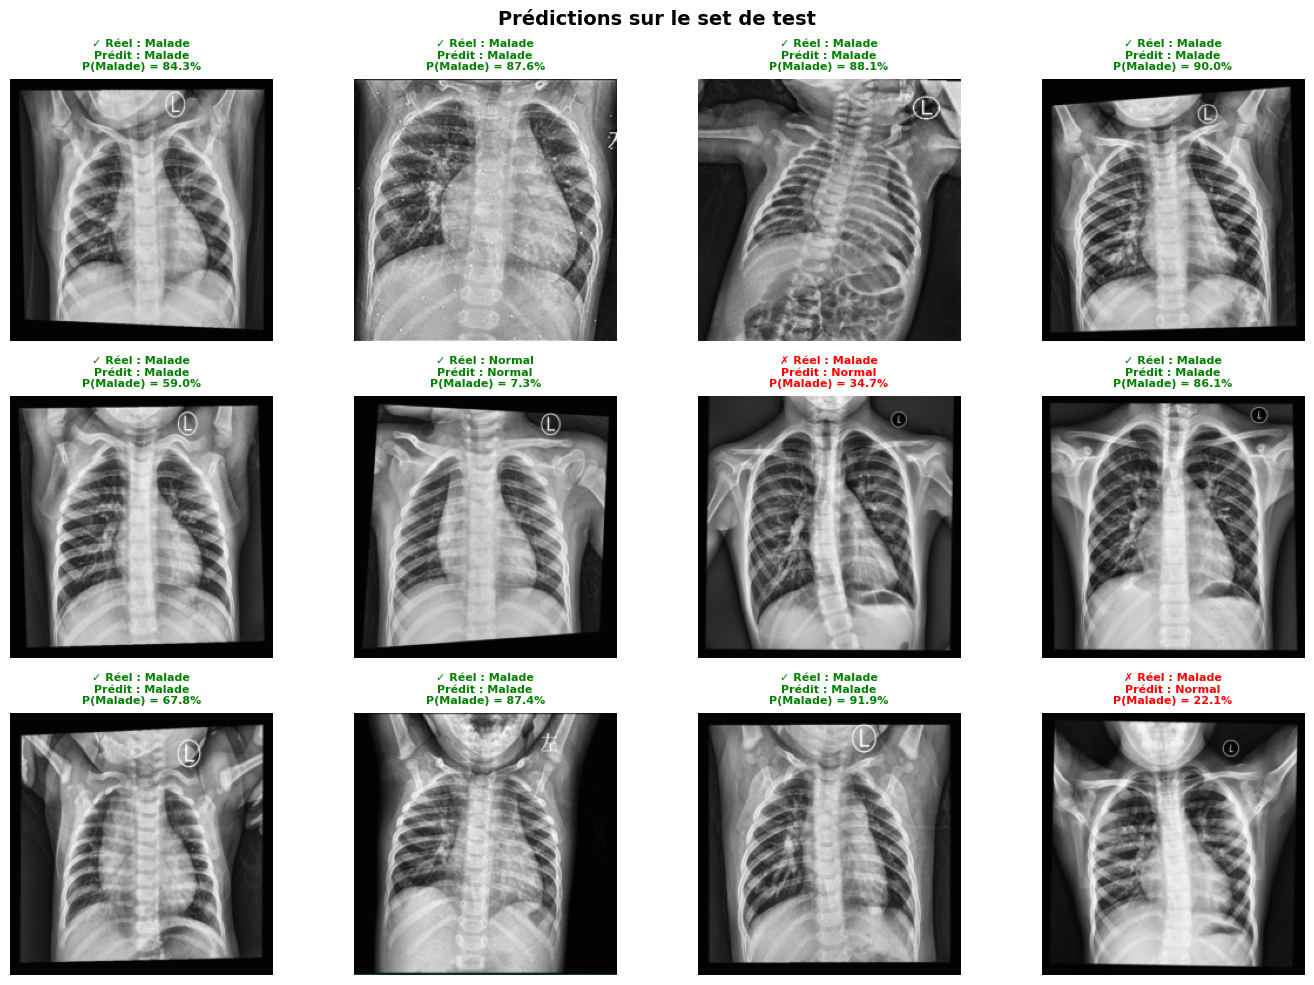

In [ ]:
def denormalize(tensor):
    m = torch.tensor(MEAN).view(3, 1, 1)
    s = torch.tensor(STD).view(3, 1, 1)
    return torch.clamp(tensor * s + m, 0, 1)

# Prendre un batch du test
images_batch, labels_batch = next(iter(test_loader))
images_batch = images_batch.to(device)

with torch.no_grad():
    outputs      = model(images_batch)
    probs_batch  = torch.softmax(outputs, dim=1).cpu()
    preds_batch  = outputs.argmax(dim=1).cpu()

n_show = min(12, len(images_batch))
fig, axes = plt.subplots(3, 4, figsize=(14, 10))
fig.suptitle('Prédictions sur le set de test', fontsize=14, fontweight='bold')

for i, ax in enumerate(axes.flatten()):
    if i >= n_show:
        ax.axis('off')
        continue

    img        = denormalize(images_batch[i].cpu()).permute(1, 2, 0).numpy()
    true_label = CLASS_NAMES[labels_batch[i]]
    pred_label = CLASS_NAMES[preds_batch[i]]
    prob_malade= probs_batch[i][1].item()   # Proba d'être Malade
    correct    = (true_label == pred_label)

    ax.imshow(img)
    ax.axis('off')
    color  = 'green' if correct else 'red'
    symbol = '✓' if correct else '✗'
    ax.set_title(
        f"{symbol} Réel : {true_label}\n"
        f"Prédit : {pred_label}\n"
        f"P(Malade) = {prob_malade:.1%}",
        color=color, fontsize=8, fontweight='bold'
    )

plt.tight_layout()
plt.show()

---
## 💾 Étape 16 — Sauvegarde du modèle

---
## 📊 Comparaison CNN vs ResNet18

On compare les deux modèles sur toutes les métriques clés.

| Critère | CNN (from scratch) | ResNet18 (transfer learning) |
|---------|-------------------|------------------------------|
| Poids initiaux | Aléatoires | Pré-entraînés ImageNet |
| Données nécessaires | Beaucoup | Peu |
| Temps d'entraînement | Plus long | Plus rapide |
| Performance attendue | Baseline | Meilleure |



═════════════════════════════════════════════════════════════════
              COMPARAISON FINALE — CNN vs ResNet18             
═════════════════════════════════════════════════════════════════
  Métrique        |                CNN |           ResNet18 |      Δ
─────────────────────────────────────────────────────────────────
  Accuracy        |            54.76% | 🏆          83.33% | ↑28.57%
  Precision       |            96.67% |             93.33% | ↓3.33%
  Recall          |            43.94% | 🏆          84.85% | ↑40.91%
  F1-score        |            60.42% | 🏆          88.89% | ↑28.47%
  ROC-AUC         |            76.85% | 🏆          93.69% | ↑16.84%
═════════════════════════════════════════════════════════════════


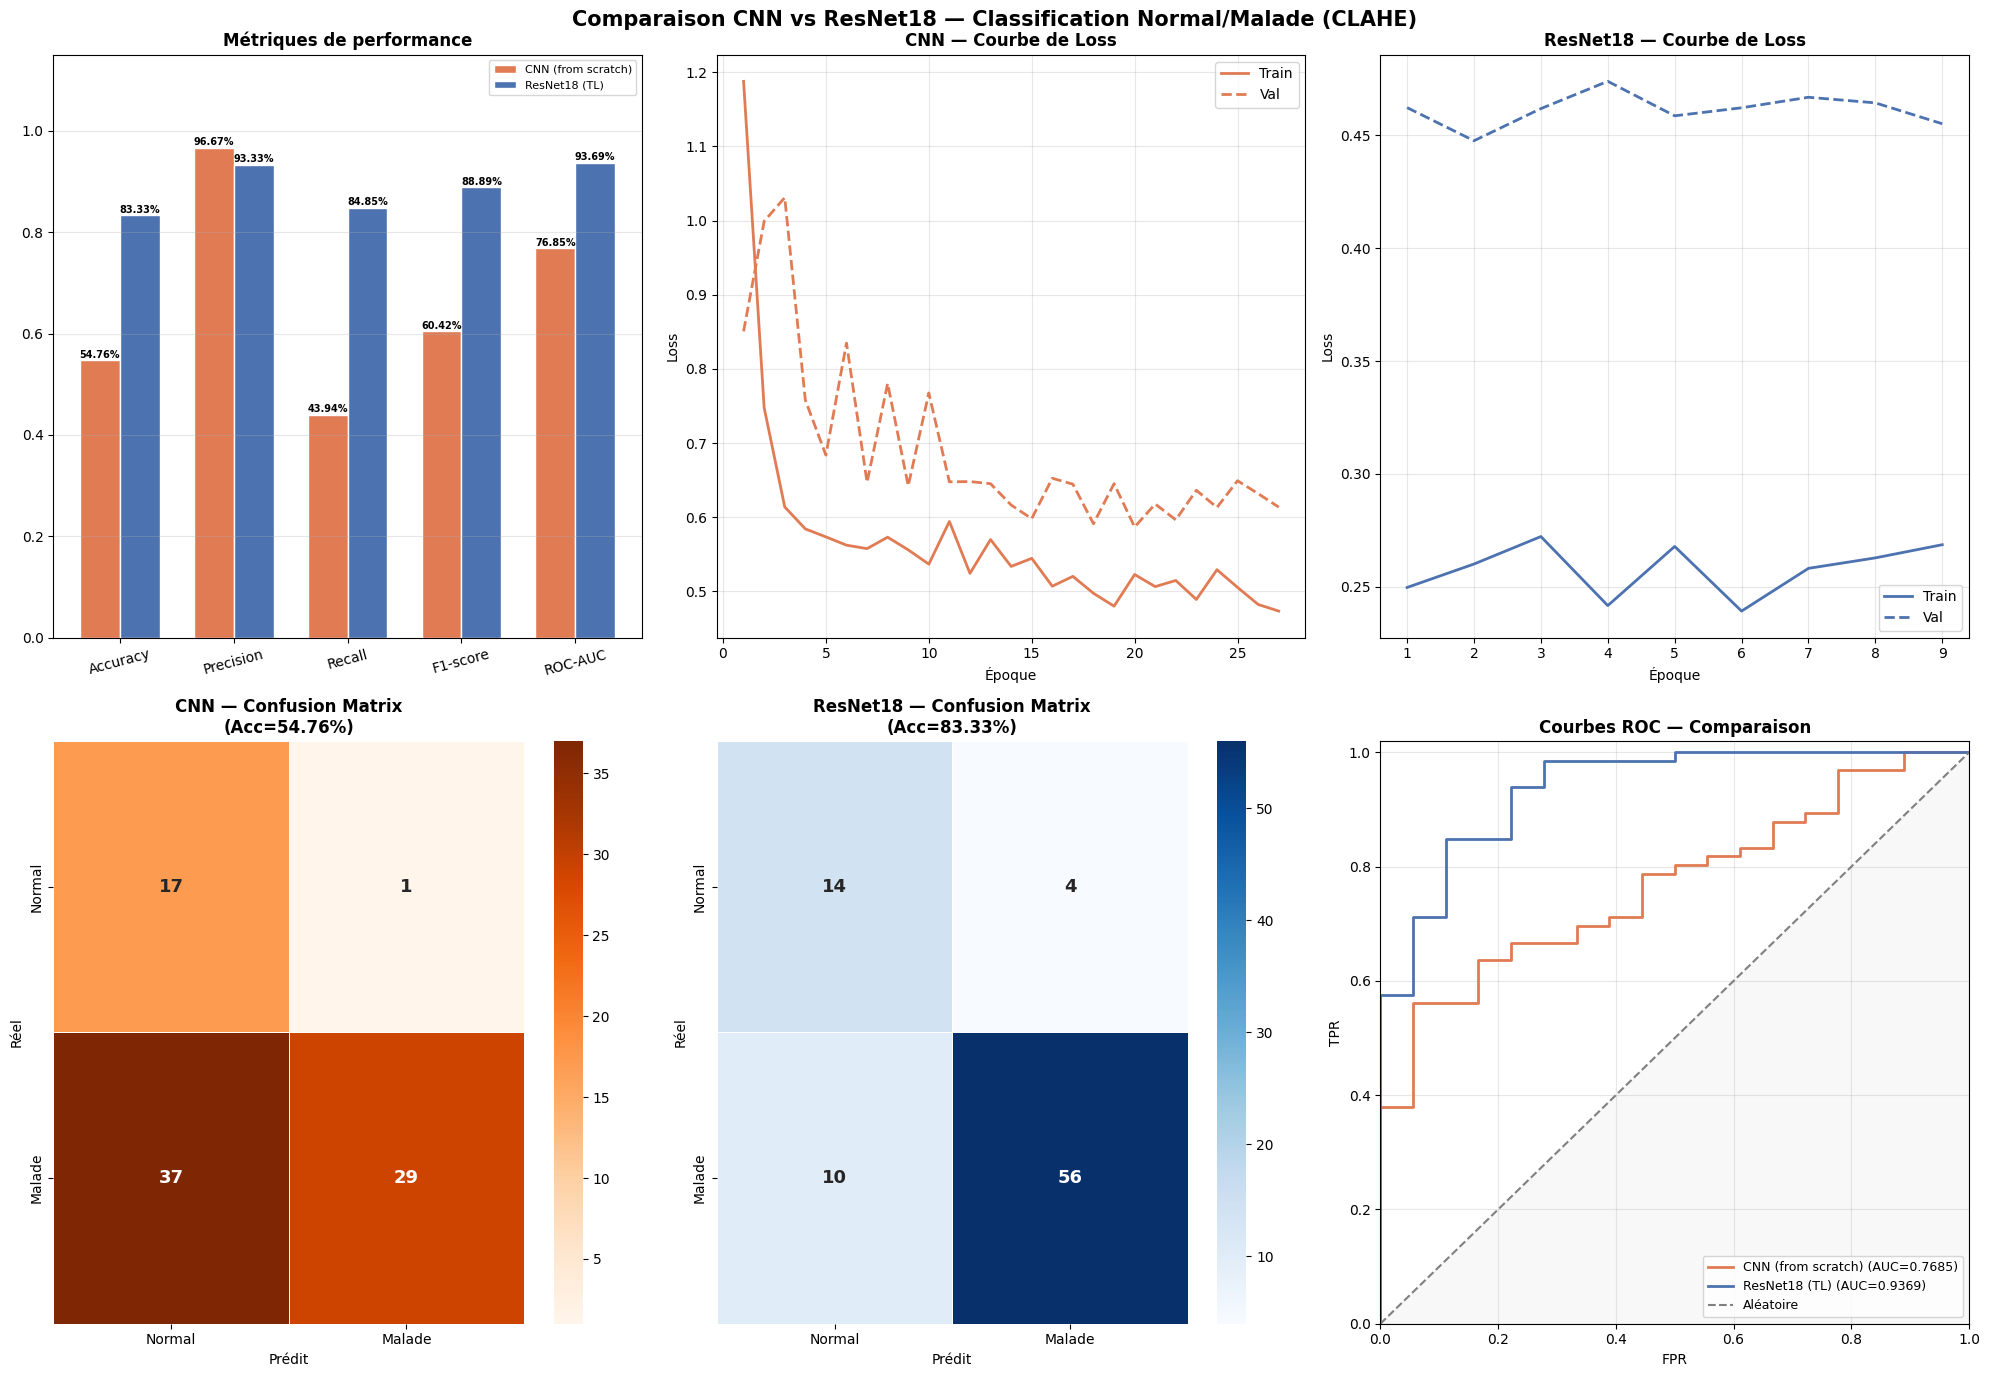


🏆 MEILLEUR MODÈLE (F1-score) : ResNet18 (TL)
   F1  CNN     : 60.42%
   F1  ResNet18: 88.89%
   Gain ResNet18 vs CNN : +28.47%
   ✅ Le Transfer Learning (ResNet18 + CLAHE) surpasse le CNN from scratch.


In [ ]:
# ══════════════════════════════════════════════════════════════════════════
#  COMPARAISON FINALE : CNN vs ResNet18 (avec CLAHE)
# ══════════════════════════════════════════════════════════════════════════

# Stocker les résultats ResNet18
results_resnet = {
    'accuracy' : accuracy,
    'precision': precision,
    'recall'   : recall,
    'f1'       : f1,
    'roc_auc'  : roc_auc,
    'history'  : history,
    'preds'    : all_preds,
    'labels'   : all_labels,
    'probs'    : all_probs,
}

models_results = {
    'CNN (from scratch)' : results_cnn,
    'ResNet18 (TL)'      : results_resnet,
}

metrics_names = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
metrics_labels = ['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC']

# ── Tableau de comparaison ────────────────────────────────────────────────
print('\n' + '═' * 65)
print(f'  {"COMPARAISON FINALE — CNN vs ResNet18":^61}')
print('═' * 65)
print(f'  {"Métrique":15} | {"CNN":>18} | {"ResNet18":>18} | {"Δ":>6}')
print('─' * 65)

for m, label in zip(metrics_names, metrics_labels):
    v_cnn    = results_cnn[m]
    v_resnet = results_resnet[m]
    delta    = v_resnet - v_cnn
    arrow    = '↑' if delta > 0 else ('↓' if delta < 0 else '=')
    winner   = '🏆' if v_resnet > v_cnn else ('  ' if v_resnet == v_cnn else '  ')
    print(f'  {label:15} | {v_cnn:>17.2%} | {winner}{v_resnet:>16.2%} | {arrow}{abs(delta):.2%}')

print('═' * 65)

# ── Visualisation côte à côte ─────────────────────────────────────────────
fig = plt.figure(figsize=(20, 14))
fig.suptitle('Comparaison CNN vs ResNet18 — Classification Normal/Malade (CLAHE)',
             fontsize=15, fontweight='bold')

colors = {'CNN (from scratch)': '#E07B54', 'ResNet18 (TL)': '#4C72B0'}

# -- Graphe 1 : Barres des métriques --
ax1 = fig.add_subplot(2, 3, 1)
x    = np.arange(len(metrics_labels))
width = 0.35
for j, (name, res) in enumerate(models_results.items()):
    vals = [res[m] for m in metrics_names]
    bars = ax1.bar(x + j * width, vals, width, label=name,
                   color=list(colors.values())[j],
                   edgecolor='white', linewidth=1)
    for bar, v in zip(bars, vals):
        ax1.text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 0.005,
                 f'{v:.2%}', ha='center', fontsize=7, fontweight='bold')
ax1.set_xticks(x + width / 2)
ax1.set_xticklabels(metrics_labels, rotation=15)
ax1.set_ylim(0, 1.15)
ax1.set_title('Métriques de performance', fontweight='bold')
ax1.legend(fontsize=8)
ax1.grid(axis='y', alpha=0.3)

# -- Graphe 2 : Loss CNN --
ax2 = fig.add_subplot(2, 3, 2)
ep_cnn = range(1, len(history_cnn['train_loss']) + 1)
ax2.plot(ep_cnn, history_cnn['train_loss'], color='#E07B54', label='Train', lw=2)
ax2.plot(ep_cnn, history_cnn['val_loss'],   color='#E07B54', label='Val',   lw=2, ls='--')
ax2.set_title('CNN — Courbe de Loss', fontweight='bold')
ax2.set_xlabel('Époque'); ax2.set_ylabel('Loss')
ax2.legend(); ax2.grid(alpha=0.3)

# -- Graphe 3 : Loss ResNet --
ax3 = fig.add_subplot(2, 3, 3)
ep_res = range(1, len(history['train_loss']) + 1)
ax3.plot(ep_res, history['train_loss'], color='#4C72B0', label='Train', lw=2)
ax3.plot(ep_res, history['val_loss'],   color='#4C72B0', label='Val',   lw=2, ls='--')
ax3.set_title('ResNet18 — Courbe de Loss', fontweight='bold')
ax3.set_xlabel('Époque'); ax3.set_ylabel('Loss')
ax3.legend(); ax3.grid(alpha=0.3)

# -- Graphe 4 : Confusion matrix CNN --
ax4 = fig.add_subplot(2, 3, 4)
cm_cnn = confusion_matrix(cnn_labels, cnn_preds)
sns.heatmap(cm_cnn, annot=True, fmt='d', cmap='Oranges',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            linewidths=0.5, ax=ax4, annot_kws={'size': 13, 'weight': 'bold'})
ax4.set_title(f'CNN — Confusion Matrix\n(Acc={cnn_accuracy:.2%})', fontweight='bold')
ax4.set_xlabel('Prédit'); ax4.set_ylabel('Réel')

# -- Graphe 5 : Confusion matrix ResNet --
ax5 = fig.add_subplot(2, 3, 5)
cm_res = confusion_matrix(all_labels, all_preds)
sns.heatmap(cm_res, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            linewidths=0.5, ax=ax5, annot_kws={'size': 13, 'weight': 'bold'})
ax5.set_title(f'ResNet18 — Confusion Matrix\n(Acc={accuracy:.2%})', fontweight='bold')
ax5.set_xlabel('Prédit'); ax5.set_ylabel('Réel')

# -- Graphe 6 : Courbes ROC superposées --
ax6 = fig.add_subplot(2, 3, 6)
for name, res, col in zip(
        models_results.keys(),
        models_results.values(),
        colors.values()):
    fpr_m, tpr_m, _ = roc_curve(res['labels'], res['probs'])
    ax6.plot(fpr_m, tpr_m, color=col, lw=2,
             label=f'{name} (AUC={res["roc_auc"]:.4f})')
ax6.plot([0,1],[0,1],'--', color='gray', lw=1.5, label='Aléatoire')
ax6.fill_between([0,1],[0,1], alpha=0.05, color='gray')
ax6.set_title('Courbes ROC — Comparaison', fontweight='bold')
ax6.set_xlabel('FPR'); ax6.set_ylabel('TPR')
ax6.legend(fontsize=9, loc='lower right')
ax6.grid(alpha=0.3)
ax6.set_xlim([0,1]); ax6.set_ylim([0,1.02])

plt.tight_layout()
plt.show()

# ── Conclusion ────────────────────────────────────────────────────────────
winner_name = max(models_results, key=lambda k: models_results[k]['f1'])
print(f'\n🏆 MEILLEUR MODÈLE (F1-score) : {winner_name}')
print(f'   F1  CNN     : {results_cnn["f1"]:.2%}')
print(f'   F1  ResNet18: {results_resnet["f1"]:.2%}')
delta_f1 = results_resnet['f1'] - results_cnn['f1']
print(f'   Gain ResNet18 vs CNN : {delta_f1:+.2%}')
if delta_f1 > 0:
    print('   ✅ Le Transfer Learning (ResNet18 + CLAHE) surpasse le CNN from scratch.')
elif delta_f1 < 0:
    print('   ⚠️  Le CNN from scratch surpasse ResNet18 — vérifier le fine-tuning.')
else:
    print('   ➡️  Les deux modèles sont équivalents.')


In [ ]:
torch.save({
    'model_state_dict' : model.state_dict(),
    'architecture'     : 'ResNet18 (Binary)',
    'classes'          : CLASS_NAMES,
    'binary_map'       : BINARY_MAP,
    'num_classes'      : NUM_CLASSES,
    'img_size'         : IMG_SIZE,
    'test_accuracy'    : float(accuracy),
    'test_f1'          : float(f1),
    'test_roc_auc'     : float(roc_auc),
    'config': {
        'couches_gelées'  : 'conv1, bn1, layer1, layer2, layer3',
        'couches_entraîn' : 'layer4 + fc',
        'optimizer'       : f'AdamW (lr={LEARNING_RATE}, wd={WEIGHT_DECAY})',
        'loss'            : 'Weighted CE + LabelSmoothing(0.1)',
        'sampler'         : 'WeightedRandomSampler',
        'batch_size'      : BATCH_SIZE,
        'split'           : '80/10/10',
        'early_stopping'  : f'patience={PATIENCE}'
    }
}, 'modele_binaire_normal_malade.pth')

print("✅ Modèle sauvegardé : modele_binaire_normal_malade.pth")
print(f"\n{'═'*50}")
print(f"  🏆 RÉSULTATS FINAUX")
print(f"{'═'*50}")
print(f"  Accuracy   : {accuracy:.2%}")
print(f"  F1-score   : {f1:.2%}")
print(f"  ROC-AUC    : {roc_auc:.4f}")
print(f"  TN/FP/FN/TP: {tn}/{fp}/{fn}/{tp}")
print(f"{'═'*50}")

✅ Modèle sauvegardé : modele_binaire_normal_malade.pth

══════════════════════════════════════════════════
  🏆 RÉSULTATS FINAUX
══════════════════════════════════════════════════
  Accuracy   : 82.14%
  F1-score   : 88.55%
  ROC-AUC    : 0.8535
  TN/FP/FN/TP: 11/7/8/58
══════════════════════════════════════════════════


---
## 🔮 Bonus — Prédire une nouvelle image

In [ ]:
def predire_binaire(chemin_image, model, class_names, device):
    """
    Prédit si une image est Normal ou Malade.

    Affiche :
    - L'image
    - La prédiction avec confiance
    - La barre de probabilités Normal vs Malade
    """
    image  = Image.open(chemin_image).convert('RGB')
    tensor = val_transforms(image).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        output = model(tensor)
        probs  = torch.softmax(output, dim=1)[0].cpu().numpy()
        pred   = class_names[probs.argmax()]

    # Couleur selon le diagnostic
    color = 'red' if pred == 'Malade' else 'green'

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

    ax1.imshow(image, cmap='gray')
    ax1.set_title(
        f'Diagnostic : {pred}\nConfiance : {probs.max():.1%}',
        fontsize=14, fontweight='bold', color=color
    )
    ax1.axis('off')

    bar_colors = ['#4C72B0', '#C44E52']   # Bleu = Normal, Rouge = Malade
    bars = ax2.barh(class_names, probs * 100,
                    color=bar_colors, edgecolor='white', linewidth=1.2)
    ax2.set_xlabel('Probabilité (%)')
    ax2.set_title('Score de confiance')
    ax2.set_xlim(0, 105)
    ax2.axvline(x=50, color='gray', linestyle='--', linewidth=1, label='Seuil 50%')
    ax2.legend(fontsize=9)

    for bar, p in zip(bars, probs):
        ax2.text(
            bar.get_width() + 1,
            bar.get_y() + bar.get_height() / 2,
            f'{p * 100:.1f}%', va='center', fontsize=11, fontweight='bold'
        )

    plt.tight_layout()
    plt.show()
    return pred, probs


# ── Utilisation ───────────────────────────────────────────────────────────
# chemin = "/chemin/vers/image.jpg"
# resultat, probs = predire_binaire(chemin, model, CLASS_NAMES, device)
# print(f"Diagnostic : {resultat}")

print("✅ Fonction predire_binaire prête !")
print("   Décommentez les 3 lignes et remplacez le chemin pour l'utiliser.")

✅ Fonction predire_binaire prête !
   Décommentez les 3 lignes et remplacez le chemin pour l'utiliser.


---

## ✅ Récapitulatif — Classification Binaire

### Pipeline complet

| Étape | Détail |
|---|---|
| **Regroupement** | ASD + PDA + VSD → Malade (1) / Normal → Normal (0) |
| **Déséquilibre** | 208 Normal vs 620 Malade (ratio 1:3) |
| **Anti-déséquilibre** | WeightedRandomSampler + Weighted Loss |
| **Architecture** | ResNet18 (layer4 + fc entraînés) |
| **Dropout** | 0.5 avant la couche finale |
| **Loss** | Weighted CrossEntropy + Label Smoothing 0.1 |
| **Optimiseur** | AdamW (lr=1e-4, wd=1e-4) |
| **Scheduler** | ReduceLROnPlateau (patience=3, factor=0.5) |
| **Gradient Clipping** | max_norm=1.0 |
| **Early Stopping** | patience=5 |
| **Métriques** | Accuracy + Precision + Recall + **F1** + **ROC-AUC** |

### Métriques prioritaires pour ce problème médical

| Métrique | Importance médicale |
|---|---|
| **Recall (Malade)** | ⚠️ Critique — manquer un malade est dangereux |
| **F1-score** | Équilibre Precision/Recall |
| **ROC-AUC** | Performance globale de discrimination |
| Accuracy | Secondaire (dataset déséquilibré) |